# Módulo 54: Series de tiempo

Autor: Juliho Castillo Colmenares

> Lección complementaria del ejercicio [m54-series-de-tiempo-solucion.ipynb](m54-series-de-tiempo-solucion.ipynb). No es una tarea entregada del programa.

Una **serie de tiempo** es una sucesión de observaciones ordenadas en el tiempo: precios diarios, ventas mensuales, temperaturas anuales. A diferencia de una tabla común, aquí el orden importa: cada valor depende de los anteriores. Eso cambia cómo se describen los datos, cómo se correlacionan y cómo se pronostican. Para no depender de una descarga, todas las series de esta lección se **simulan**:

1. Qué es una serie de tiempo
2. Componentes: tendencia, estacionalidad y residuo
3. Descomposición con `seasonal_decompose` y la elección de `period`
4. Correlación espuria y rendimientos
5. Autocorrelación y la gráfica ACF
6. Estacionariedad débil
7. La prueba ADF
8. Media móvil y pronóstico ingenuo
9. Errores frecuentes
10. Ejercicio

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller, acf
from statsmodels.graphics.tsaplots import plot_acf

## 1. Qué es una serie de tiempo

Formalmente es una colección $\{y_t\}$ indexada por el tiempo $t = 1, 2, \dots, n$, con un intervalo fijo entre observaciones. En pandas se representa con una `Series` cuyo índice son fechas y tiene una **frecuencia**: `"B"` para días hábiles, `"MS"` para inicios de mes, `"YS"` para años.

Se simulan cinco años de días hábiles (252 por año, unos 1.260 días) para dos activos independientes cuyos precios siguen una **caminata aleatoria** geométrica: cada día el logaritmo del precio cambia por un ruido independiente.

In [2]:
rng = np.random.default_rng(42)
fechas = pd.bdate_range("2019-01-01", periods=1260)       # frecuencia "B": días hábiles

ruido_a = rng.normal(0.0003, 0.015, len(fechas))
ruido_b = rng.normal(0.0003, 0.015, len(fechas))
precios = pd.DataFrame({"A": 100 * np.exp(np.cumsum(ruido_a)),
                        "B": 50 * np.exp(np.cumsum(ruido_b))}, index=fechas)
print(precios.index.freq)
precios.head()

<BusinessDay>


,A,B
2019-01-01,100.488264,50.770377
2019-01-02,98.962519,50.859872
2019-01-03,100.112840,51.486051
2019-01-04,101.565755,51.157216
2019-01-07,98.666048,51.134539


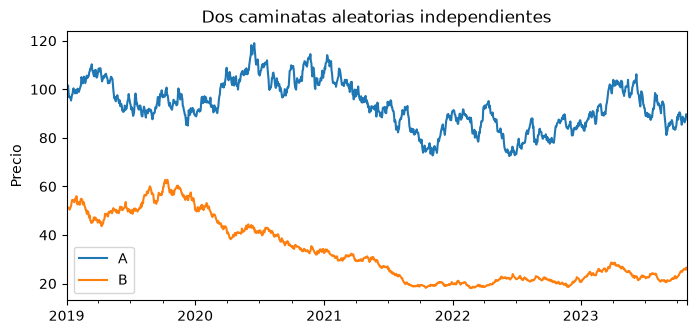

In [3]:
fig, ax = plt.subplots(figsize=(8, 3.5))
precios.plot(ax=ax)
ax.set_title("Dos caminatas aleatorias independientes")
ax.set_ylabel("Precio")
plt.show()

## 2. Componentes: tendencia, estacionalidad y residuo

Muchas series se entienden como la combinación de tres partes:

| Componente | Símbolo | Descripción |
| --- | --- | --- |
| Tendencia | $T_t$ | Movimiento de largo plazo |
| Estacionalidad | $S_t$ | Patrón que se repite con un período fijo $m$ |
| Residuo | $R_t$ | Lo que queda: variación irregular |

En el modelo **aditivo**, $y_t = T_t + S_t + R_t$, la amplitud estacional es constante. En el **multiplicativo**, $y_t = T_t \cdot S_t \cdot R_t$, la estacionalidad crece con el nivel de la serie; tomando logaritmos se vuelve aditivo: $\ln y_t = \ln T_t + \ln S_t + \ln R_t$.

Se simula una serie de demanda diaria en días hábiles con tendencia lineal y un ciclo anual de 252 días.

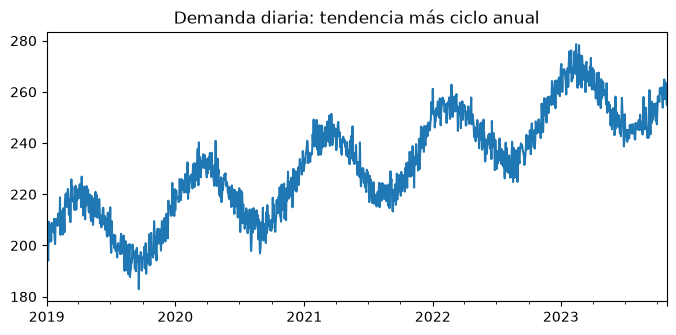

In [4]:
t = np.arange(len(fechas))
demanda = pd.Series(200 + 0.05 * t + 15 * np.sin(2 * np.pi * t / 252) + rng.normal(0, 4, len(t)),
                    index=fechas, name="demanda")

fig, ax = plt.subplots(figsize=(8, 3.5))
demanda.plot(ax=ax)
ax.set_title("Demanda diaria: tendencia más ciclo anual")
plt.show()

## 3. Descomposición con `seasonal_decompose` y la elección de `period`

`seasonal_decompose` estima la tendencia con una media móvil centrada de longitud `period`, resta esa tendencia, promedia lo que queda en cada posición del ciclo para obtener $S_t$ y deja el resto en $R_t$.

El parámetro `period` es el número de **observaciones** por ciclo, no de días del calendario. Con datos de días hábiles, un año tiene unas **252** observaciones, no 365. Con un período equivocado, el patrón estacional se promedia mal y termina en el residuo.

period=252: amplitud estacional= 38.3, desviación del residuo= 3.49
period=365: amplitud estacional= 23.3, desviación del residuo=12.87


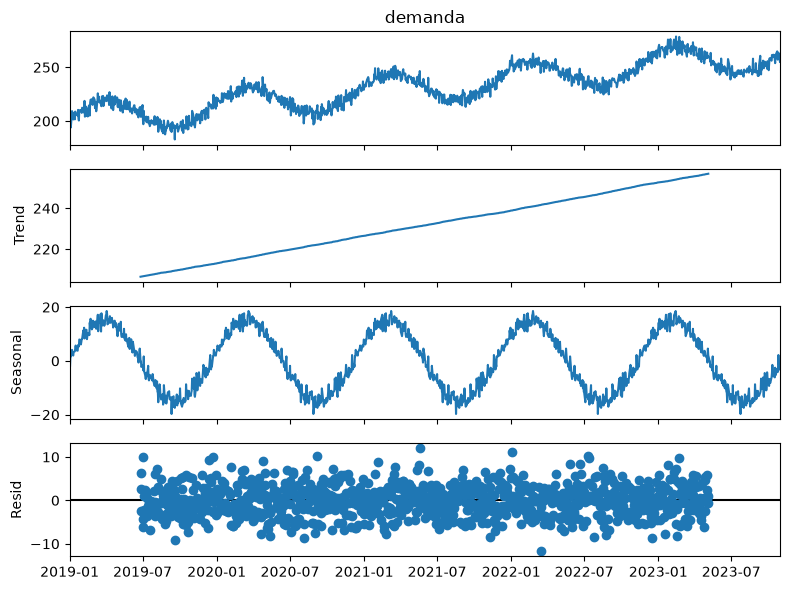

In [5]:
for periodo in [252, 365]:
    d = seasonal_decompose(demanda, model="additive", period=periodo)
    amplitud = d.seasonal.max() - d.seasonal.min()
    print(f"period={periodo}: amplitud estacional={amplitud:5.1f}, "
          f"desviación del residuo={d.resid.std():5.2f}")

descomposicion = seasonal_decompose(demanda, model="additive", period=252)
fig = descomposicion.plot()
fig.set_size_inches(8, 6)
plt.tight_layout()
plt.show()

Con `period=252` la desviación del residuo (3.5) es parecida a la del ruido simulado (4). La amplitud estacional estimada (38) supera a la real (30, de −15 a +15) porque cada posición del ciclo se promedia con solo unos cuatro años y conserva algo de ruido. Con `period=365` buena parte del ciclo queda sin explicar y el residuo casi se cuadruplica (12.9).

## 4. Correlación espuria y rendimientos

Dos series con tendencia, o dos caminatas aleatorias, suelen mostrar correlaciones altas entre sus **niveles** aunque no tengan ninguna relación: ambas se mueven lentamente y cualquier deriva común parece asociación. Es una **correlación espuria**.

Para comparar activos se usan los **rendimientos logarítmicos**, que eliminan la tendencia:

$$r_t = \ln\!\left(\frac{P_t}{P_{t-1}}\right) = \ln P_t - \ln P_{t-1}.$$

In [6]:
rendimientos = np.log(precios).diff().dropna()

print(f"Correlación de los precios:      {precios['A'].corr(precios['B']):.3f}")
print(f"Correlación de los rendimientos: {rendimientos['A'].corr(rendimientos['B']):.3f}")

# Con muchas parejas de caminatas independientes, ¿qué tan grandes salen las correlaciones de niveles?
corr_niveles = [np.corrcoef(np.cumsum(rng.normal(size=1260)), np.cumsum(rng.normal(size=1260)))[0, 1]
                for _ in range(200)]
print(f"200 parejas independientes: |correlación de niveles| > 0.5 en el "
      f"{np.mean(np.abs(corr_niveles) > 0.5):.0%} de los casos")

Correlación de los precios:      0.500
Correlación de los rendimientos: 0.033
200 parejas independientes: |correlación de niveles| > 0.5 en el 34% de los casos


Los precios de estos dos activos simulados, independientes por construcción, tienen una correlación de niveles de 0.50, mientras que la de sus rendimientos es prácticamente nula (0.03). Entre 200 parejas de caminatas independientes, el 34 % supera 0.5 en valor absoluto sin ninguna relación real.

## 5. Autocorrelación y la gráfica ACF

La **autocorrelación** de orden $k$ mide la correlación de la serie consigo misma desplazada $k$ períodos:

$$\rho_k = \frac{\operatorname{Cov}(y_t, y_{t-k})}{\operatorname{Var}(y_t)}, \qquad \hat\rho_k = \frac{\sum_{t=k+1}^{n} (y_t - \bar y)(y_{t-k} - \bar y)}{\sum_{t=1}^{n} (y_t - \bar y)^2}.$$

La gráfica **ACF** dibuja $\hat\rho_k$ para varios rezagos. La banda sombreada es aproximadamente $\pm 1.96/\sqrt{n}$: si la serie fuera ruido blanco, el 95 % de las barras caería dentro.

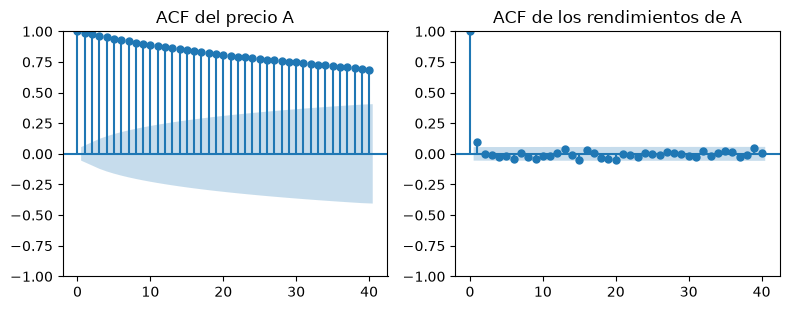

Banda aproximada ±1.96/√n = ±0.055
Primeras autocorrelaciones del precio:      [0.989 0.977 0.964]
Primeras autocorrelaciones del rendimiento: [ 0.096 -0.003 -0.006]


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3.2))
plot_acf(precios["A"], lags=40, ax=axes[0], title="ACF del precio A")
plot_acf(rendimientos["A"], lags=40, ax=axes[1], title="ACF de los rendimientos de A")
plt.tight_layout()
plt.show()

print(f"Banda aproximada ±1.96/√n = ±{1.96 / np.sqrt(len(rendimientos)):.3f}")
print("Primeras autocorrelaciones del precio:     ", acf(precios["A"], nlags=3)[1:].round(3))
print("Primeras autocorrelaciones del rendimiento:", acf(rendimientos["A"], nlags=3)[1:].round(3))

El precio tiene autocorrelaciones cercanas a 1 que decaen muy despacio, la huella de una caminata aleatoria. Los rendimientos se comportan como ruido blanco: sus barras quedan dentro de la banda salvo alguna excepción, como el rezago 1 (0.096), que aquí es fruto del azar porque los rendimientos se simularon independientes. Con 40 rezagos, se esperan unas dos barras fuera de la banda aunque no haya ninguna dependencia.

## 6. Estacionariedad débil

Una serie es **débilmente estacionaria** si:

1. Su media $E[y_t] = \mu$ es constante en el tiempo.
2. Su varianza $\operatorname{Var}(y_t) = \sigma^2$ es constante.
3. Su autocovarianza $\operatorname{Cov}(y_t, y_{t-k})$ depende solo del rezago $k$, no de $t$.

Una serie con tendencia viola la condición 1; una caminata aleatoria viola la 2, porque su varianza crece con $t$. Muchos modelos de pronóstico, como los AR y ARIMA de los próximos módulos, suponen estacionariedad.

In [8]:
# Varianza de una caminata aleatoria en distintos momentos, con 2.000 trayectorias simuladas
trayectorias = np.cumsum(rng.normal(size=(2000, 500)), axis=1)
for momento in [10, 100, 499]:
    print(f"t={momento:>3}: varianza entre trayectorias = {trayectorias[:, momento].var():6.1f}")

t= 10: varianza entre trayectorias =   10.8
t=100: varianza entre trayectorias =  101.2
t=499: varianza entre trayectorias =  478.1


La varianza crece aproximadamente como $t$: la caminata aleatoria no es estacionaria.

## 7. La prueba ADF

La prueba de **Dickey–Fuller aumentada** (ADF) estima la regresión

$$\Delta y_t = \alpha + \beta t + \gamma\, y_{t-1} + \sum_{i=1}^{q} \delta_i\, \Delta y_{t-i} + \varepsilon_t,$$

donde los rezagos $\Delta y_{t-i}$ absorben la autocorrelación. Las hipótesis son:

- $H_0: \gamma = 0$, la serie tiene **raíz unitaria** (no es estacionaria).
- $H_1: \gamma < 0$, la serie es estacionaria (alrededor de una constante, o de una tendencia si se incluye $\beta t$).

Un p-valor pequeño permite rechazar la raíz unitaria. En `adfuller`, `regression="c"` incluye solo la constante y `regression="ct"`, constante y tendencia.

In [9]:
def resumen_adf(serie, nombre, regression="c"):
    estadistico, p_valor, rezagos, *_ = adfuller(serie, regression=regression)
    decision = "estacionaria" if p_valor < 0.05 else "no se rechaza la raíz unitaria"
    print(f"{nombre:<28} ADF={estadistico:7.2f}  p={p_valor:.4f}  -> {decision}")

resumen_adf(precios["A"], "Precio A")
resumen_adf(rendimientos["A"], "Rendimientos de A")

desestacionalizada = demanda - descomposicion.seasonal      # se quita el ciclo anual
resumen_adf(desestacionalizada, "Demanda desest. (c)")
resumen_adf(desestacionalizada, "Demanda desest. (ct)", regression="ct")

Precio A                     ADF=  -2.81  p=0.0566  -> no se rechaza la raíz unitaria
Rendimientos de A            ADF= -32.19  p=0.0000  -> estacionaria
Demanda desest. (c)          ADF=  -0.18  p=0.9404  -> no se rechaza la raíz unitaria
Demanda desest. (ct)         ADF= -36.26  p=0.0000  -> estacionaria


El precio queda justo por encima del umbral (p = 0.057): no se rechaza la raíz unitaria, aunque por poco, un recordatorio de que el p-valor también varía de una muestra a otra. Los rendimientos son claramente estacionarios. La demanda sin su ciclo anual tiene una tendencia determinista: con `regression="c"` parece no estacionaria, pero con `regression="ct"` la prueba la reconoce como estacionaria alrededor de esa tendencia.

## 8. Media móvil y pronóstico ingenuo

La **media móvil** de ventana $w$ promedia las últimas $w$ observaciones, $\bar y_t^{(w)} = \frac1w \sum_{i=0}^{w-1} y_{t-i}$, y suaviza el ruido. Dos pronósticos de referencia para el día siguiente:

| Método | Pronóstico de $y_{t+1}$ |
| --- | --- |
| Ingenuo | $\hat y_{t+1} = y_t$ |
| Media móvil | $\hat y_{t+1} = \bar y_t^{(w)}$ |

Cualquier modelo más complejo debería superar a estos dos. Se comparan en los últimos 60 días, pronosticando cada día con la información disponible hasta el día anterior.

MAE ingenuo: 1.129   MAE media móvil 30: 3.283


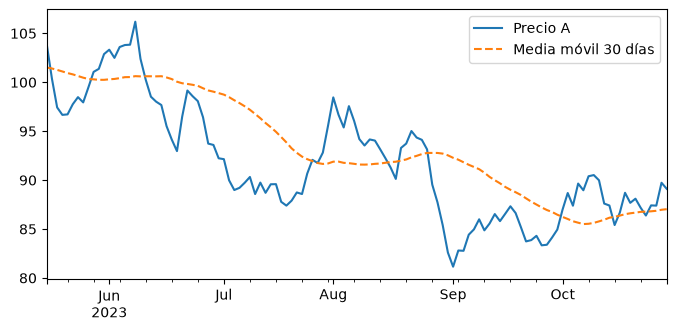

In [10]:
precio = precios["A"]
pron_ingenuo = precio.shift(1)                       # valor de ayer
pron_mm = precio.rolling(30).mean().shift(1)         # media de los 30 días anteriores

ultimos = precio.index[-60:]
mae_ingenuo = (precio[ultimos] - pron_ingenuo[ultimos]).abs().mean()
mae_mm = (precio[ultimos] - pron_mm[ultimos]).abs().mean()
print(f"MAE ingenuo: {mae_ingenuo:.3f}   MAE media móvil 30: {mae_mm:.3f}")

fig, ax = plt.subplots(figsize=(8, 3.5))
precio[-120:].plot(ax=ax, label="Precio A")
precio.rolling(30).mean()[-120:].plot(ax=ax, label="Media móvil 30 días", linestyle="--")
ax.legend()
plt.show()

Para una caminata aleatoria, el mejor pronóstico del día siguiente es el valor de hoy, así que el pronóstico ingenuo gana. La media móvil reacciona tarde: va por detrás de cada subida o bajada.

## 9. Errores frecuentes

**Correlacionar niveles de series con tendencia.** Como se vio en la sección 4, la correlación de precios puede ser alta sin ninguna relación. Para medir si dos activos se mueven juntos se correlacionan sus rendimientos.

**Usar `period=365` con datos de días hábiles.** `period` cuenta observaciones. Con datos de lunes a viernes, un año son unas 252 observaciones; con datos mensuales, 12; con datos trimestrales, 4.

**Leer "no se rechaza $H_0$" en la ADF como prueba de raíz unitaria.** La ADF tiene poca potencia con muestras cortas o con raíces cercanas a 1. Además, si la serie tiene tendencia y se usa solo `regression="c"`, el resultado puede ser engañoso:

In [11]:
cercana = np.zeros(150)
for i in range(1, 150):
    cercana[i] = 0.95 * cercana[i - 1] + rng.normal()     # estacionaria, pero con φ = 0.95
resumen_adf(cercana, "AR(1) con φ=0.95, n=150")

AR(1) con φ=0.95, n=150      ADF=  -2.42  p=0.1353  -> no se rechaza la raíz unitaria


La serie es estacionaria por construcción, pero con 150 observaciones la prueba no lo detecta.

**Pronosticar con la media móvil una serie con tendencia.** La media de las últimas $w$ observaciones queda sistemáticamente por debajo de una serie que sube:

In [12]:
sesgo = (demanda - demanda.rolling(30).mean().shift(1)).dropna().mean()
print(f"Error medio del pronóstico por media móvil en la demanda: {sesgo:.2f} (positivo: se queda corto)")

Error medio del pronóstico por media móvil en la demanda: 0.63 (positivo: se queda corto)


## 10. Ejercicio

Una tienda registra sus ventas mensuales durante 8 años. La serie es multiplicativa: la estacionalidad crece con el nivel.

```python
rng = np.random.default_rng(42)
meses = pd.date_range("2016-01-01", periods=96, freq="MS")
t = np.arange(96)
ventas = pd.Series(1000 * np.exp(0.01 * t) * (1 + 0.25 * np.sin(2 * np.pi * t / 12))
                   * np.exp(rng.normal(0, 0.03, 96)), index=meses)
```

1. Grafica la serie y elige el `period` adecuado.
2. Descompón la serie con `model="multiplicative"` e imprime el factor estacional de cada mes del primer año.
3. Aplica la ADF a la serie y a $\nabla \ln y_t$ (la diferencia del logaritmo).
4. Calcula la ACF de $\nabla \ln y_t$: ¿en qué rezago aparece la estacionalidad?
5. Compara, en los últimos 12 meses, el MAE de tres pronósticos: el ingenuo ($\hat y_{t+1} = y_t$), el ingenuo estacional ($\hat y_{t+1} = y_{t-11}$, el mismo mes del año anterior) y el ingenuo estacional corregido por el crecimiento del último año ($\hat y_{t+1} = y_{t-11}\, y_t / y_{t-12}$).

### Solución

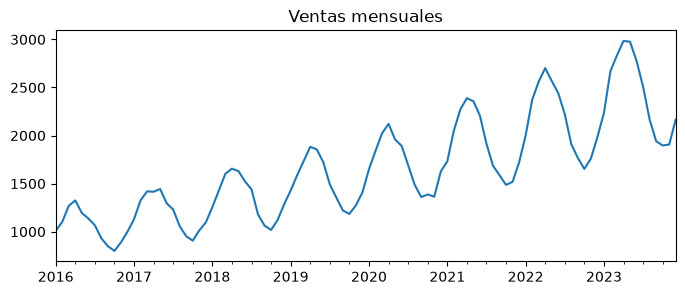

2016-01-01    0.978
2016-02-01    1.121
2016-03-01    1.212
2016-04-01    1.258
2016-05-01    1.221
2016-06-01    1.133
2016-07-01    1.014
2016-08-01    0.870
2016-09-01    0.786
2016-10-01    0.745
2016-11-01    0.785
2016-12-01    0.875
Freq: MS


In [13]:
rng = np.random.default_rng(42)
meses = pd.date_range("2016-01-01", periods=96, freq="MS")
t_m = np.arange(96)
ventas = pd.Series(1000 * np.exp(0.01 * t_m) * (1 + 0.25 * np.sin(2 * np.pi * t_m / 12))
                   * np.exp(rng.normal(0, 0.03, 96)), index=meses, name="ventas")

# 1. Datos mensuales con ciclo anual: period=12
fig, ax = plt.subplots(figsize=(8, 3))
ventas.plot(ax=ax, title="Ventas mensuales")
plt.show()

# 2. Descomposición multiplicativa
dec = seasonal_decompose(ventas, model="multiplicative", period=12)
print(dec.seasonal.iloc[:12].round(3).to_string())

In [14]:
# 3. ADF en niveles y en la diferencia del logaritmo
log_dif = np.log(ventas).diff().dropna()
resumen_adf(ventas, "Ventas")
resumen_adf(log_dif, "Diferencia del log")

# 4. ACF de la diferencia del logaritmo
rho = acf(log_dif, nlags=24)
print("Rezago con mayor autocorrelación positiva:", int(np.argmax(rho[1:])) + 1)

# 5. Tres pronósticos de referencia para cada uno de los últimos 12 meses
ultimos12 = ventas.index[-12:]
ingenuo = ventas.shift(1)                                     # mes anterior
estacional = ventas.shift(12)                                 # mismo mes del año anterior
estacional_crec = ventas.shift(12) * ventas.shift(1) / ventas.shift(13)
for nombre, pron in [("ingenuo", ingenuo), ("estacional", estacional),
                     ("estacional con crecimiento", estacional_crec)]:
    print(f"MAE {nombre:<27}: {(ventas - pron)[ultimos12].abs().mean():6.1f}")

Ventas                       ADF=   4.82  p=1.0000  -> no se rechaza la raíz unitaria
Diferencia del log           ADF=  -9.72  p=0.0000  -> estacionaria
Rezago con mayor autocorrelación positiva: 12
MAE ingenuo                    :  196.6
MAE estacional                 :  260.6
MAE estacional con crecimiento :   53.7


El factor estacional oscila alrededor de 1, entre 0.75 y 1.26, como el ciclo simulado. La diferencia del logaritmo elimina la tendencia y su ACF muestra el pico en el rezago 12. El ingenuo estacional por sí solo pierde frente al ingenuo: con un crecimiento del 1 % mensual, el mismo mes del año anterior queda cerca de un 12 % por debajo. Al corregirlo por el crecimiento del último año, el error cae a una fracción del de los otros dos.

## Resumen

- Una serie de tiempo se descompone en tendencia, estacionalidad y residuo, de forma aditiva o multiplicativa.
- En `seasonal_decompose`, `period` es el número de observaciones por ciclo: 252 para un año de días hábiles, 12 para datos mensuales.
- Las correlaciones entre niveles de series con tendencia pueden ser espurias; se comparan los rendimientos $r_t = \ln(P_t/P_{t-1})$.
- La ACF muestra la dependencia en el tiempo, y la estacionariedad débil exige media, varianza y autocovarianzas estables.
- La prueba ADF contrasta la raíz unitaria ($H_0: \gamma = 0$); un p-valor pequeño indica estacionariedad.
- El pronóstico ingenuo y la media móvil son las referencias mínimas que cualquier modelo debe superar.

En el **Módulo 55** se ajustan modelos autorregresivos AR(p), que pronostican cada valor a partir de sus propios rezagos.